In [1]:
# Ground Truth Causal Graph Definition with Adjacency Matrix

import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

Adjacency Matrix (Ground Truth):
                          batteryvoltage  sochighlevel  \
batteryvoltage                         0             1   
sochighlevel                           0             0   
energyconsumptionaverage               0             0   
electricremaining                      0             0   
mileage                                1             0   
speed_kmh                              0             0   
acceleration_kmh2                      0             0   

                          energyconsumptionaverage  electricremaining  \
batteryvoltage                                   0                  0   
sochighlevel                                     1                  1   
energyconsumptionaverage                         0                  1   
electricremaining                                0                  0   
mileage                                          1                  0   
speed_kmh                                        1              

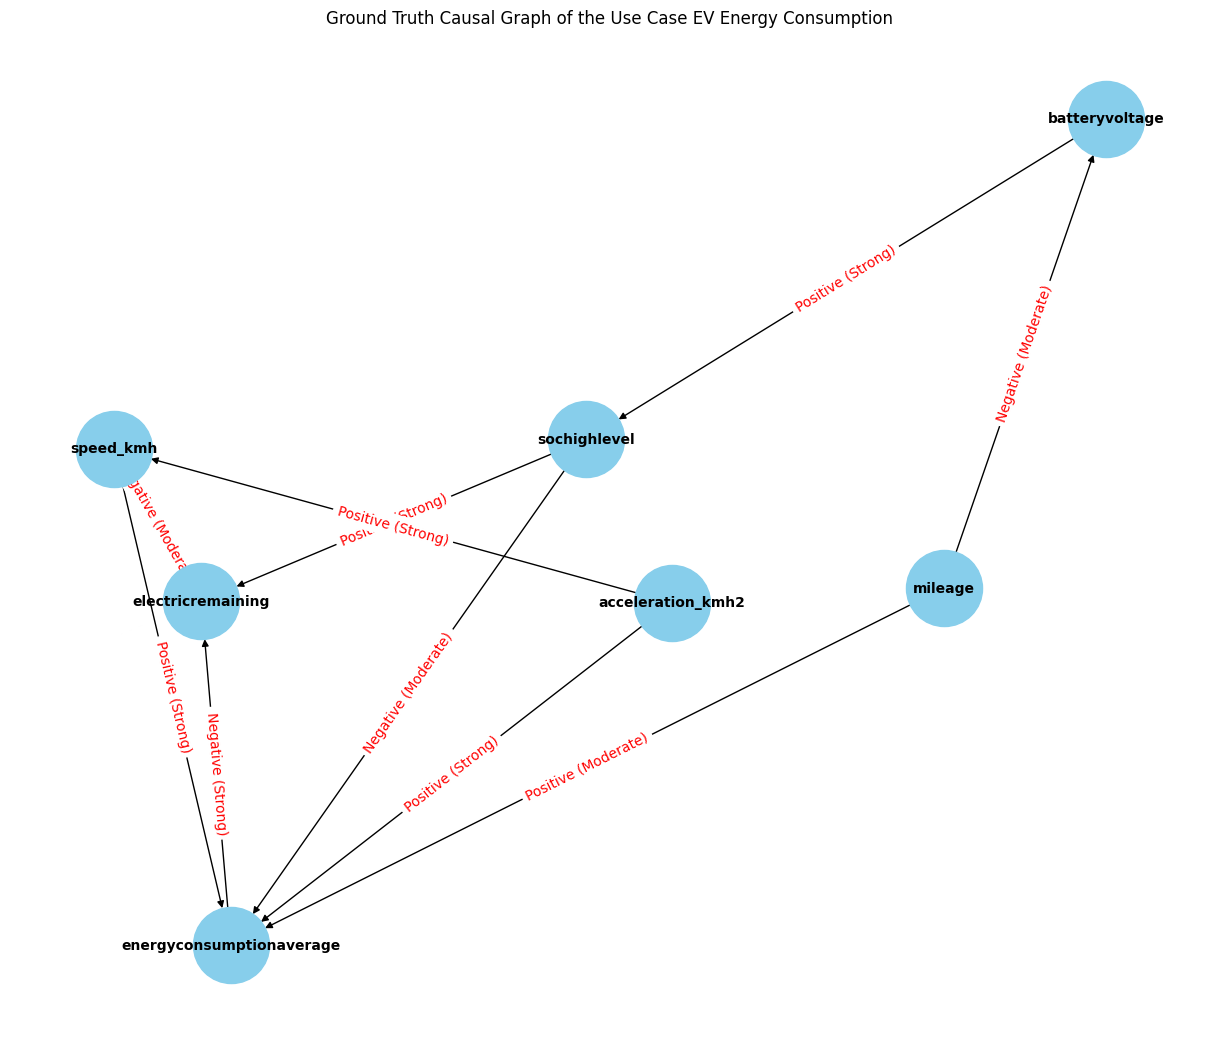

In [2]:
# Define the causal graph
G = nx.DiGraph()

# Add nodes (features)
features = [
    "batteryvoltage", "sochighlevel", "energyconsumptionaverage", "electricremaining", 
    "mileage", "speed_kmh", "acceleration_kmh2"
]
G.add_nodes_from(features)

# Define edges (causal relationships) with labels
edges = [
    ("batteryvoltage", "sochighlevel", {'label': 'Positive (Strong)'}),
    ("sochighlevel", "electricremaining", {'label': 'Positive (Strong)'}),
    ("sochighlevel", "energyconsumptionaverage", {'label': 'Negative (Moderate)'}),
    ("energyconsumptionaverage", "electricremaining", {'label': 'Negative (Strong)'}),
    ("mileage", "batteryvoltage", {'label': 'Negative (Moderate)'}),
    ("mileage", "energyconsumptionaverage", {'label': 'Positive (Moderate)'}),
    ("speed_kmh", "energyconsumptionaverage", {'label': 'Positive (Strong)'}),
    ("acceleration_kmh2", "energyconsumptionaverage", {'label': 'Positive (Strong)'}),
    ("acceleration_kmh2", "speed_kmh", {'label': 'Positive (Strong)'}),
    ("speed_kmh", "electricremaining", {'label': 'Negative (Moderate)'})
]
G.add_edges_from([(u, v) for u, v, _ in edges])

# Generate adjacency matrix
adj_matrix = nx.adjacency_matrix(G, nodelist=features).todense()
adj_df = pd.DataFrame(adj_matrix, index=features, columns=features)

# Print the adjacency matrix
print("Adjacency Matrix (Ground Truth):")
print(adj_df)

# Save the adjacency matrix as a .npy file
output_file = '../results/Ground_Truth_UC_EV_Energy_Consumption_adjacency_matrix.npy'
np.save(output_file, adj_df)

# Plot the causal graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=3000, node_color='skyblue', font_size=10, font_color='black', font_weight='bold', arrows=True)

# Add edge labels
edge_labels = {(u, v): d['label'] for u, v, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')
plt.title('Ground Truth Causal Graph of the Use Case EV Energy Consumption')
plt.show()


Ground Truth by integrating the causal relationships among **battery voltage**, **state of charge (SoC)**, **energy consumption**, **electric remaining**, **mileage**, **speed**, and **acceleration** with insights from electric vehicle (EV) performance dynamics.

**1. Battery Voltage and State of Charge (SoC):**
Battery voltage is a direct indication of the battery's state of charge.  As the battery empties, the voltage decreases, indicating a lower SoC.  Accurate SoC calculation is critical for determining remaining available energy and directing energy management measures in EVs. 
https://doi.org/10.1016/j.jclepro.2022.134381


**2. SoC and Energy Consumption:**
A higher SoC indicates a greater amount of available energy, which can accommodate increased power demands.  Nevertheless, aggressive driving behaviors, such as rapid acceleration, can result in a faster reduction of the SoC due to increased energy consumption.  Research has demonstrated that driving styles that are prone to acceleration can result in a 30% increase in energy consumption when contrasted with constant driving. https://doi.org/10.1016/j.trd.2023.103857


**3. Energy Consumption and Electric Remaining:**
The remaining electric energy in the battery is directly influenced by energy consumption.  The vehicle's range is diminished as a result of the battery's rapid depletion, which is caused by factors such as frequent acceleration or high velocities, which result in increased energy consumption.
https://publikationen.bibliothek.kit.edu/1000065370/19170488


**4. Mileage and Battery Voltage:**
As the vehicle accumulates mileage, the battery may undergo degradation, which can impact its voltage characteristics through time.  The lifespan of a battery is influenced by factors such as the extent of discharge, charge/discharge rates, and operating temperatures.  By optimizing these factors, it is possible to reduce degradation and preserve battery performance at increased mileages.
https://doi.org/10.1016/j.commtr.2024.100148

**5. Speed, Acceleration, and Energy Consumption:**
Higher speeds and faster acceleration require more power, which increases energy consumption.  Energy management solutions that optimize speed and acceleration profiles can help hybrid electric vehicles save energy and reduce pollutants.
https://doi.org/10.1016/j.applthermaleng.2024.124013

Understanding these interrelationships and incorporating results from credible sources allows us to create more accurate models for predicting and improving EV performance.  This Groubnd Truth integration helps to refine energy management strategy, increase battery longevity, and improve overall vehicle efficiency.